# Computation of Exposure Map using sat's FoV

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ROOT, glob

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [2]:
dirDir= "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
dataPath = "/dpnc/beegfs/dampe/prod/FM/skim/6.0.0/v2/2016/01/"
filenames = [dataPath + "01_data_photon.root"]

In [3]:
for filename in filenames:
    # Get all files matching the pattern
    # Use glob to find all files that match the pattern
    files = sorted(glob.glob(filename))
print(files)


['/dpnc/beegfs/dampe/prod/FM/skim/6.0.0/v2/2016/01/01_data_photon.root']


In [4]:
treename='HousekeepingData/SatStatus'

rdf = ROOT.RDataFrame(treename, files)


Warning in <TClass::Init>: no dictionary for class DmpEvtBgoRaw is available
Warning in <TClass::Init>: no dictionary for class DmpEvtPsdHits is available
Warning in <TClass::Init>: no dictionary for class DmpEvtBgoHits is available
Warning in <TClass::Init>: no dictionary for class DmpEvtHeader is available
Warning in <TClass::Init>: no dictionary for class DmpFeeNavig is available
Warning in <TClass::Init>: no dictionary for class DmpStkSiCluster is available
Warning in <TClass::Init>: no dictionary for class DmpStkLadderAdc is available
Warning in <TClass::Init>: no dictionary for class DmpStkEventMetadata is available
Warning in <TClass::Init>: no dictionary for class DmpStkTrack is available
Warning in <TClass::Init>: no dictionary for class DmpStkTrackParams is available
Warning in <TClass::Init>: no dictionary for class DmpEvtNudRaw is available
Warning in <TClass::Init>: no dictionary for class DmpEvtPsdRec is available
Warning in <TClass::Init>: no dictionary for class DmpEvtB

In [5]:
print("Created RDataFrame")
df = rdf.AsNumpy(['DmpHKDSatStatus.fSecond', 'DmpHKDSatStatus.fMicrosecond',
                   'DmpHKDSatStatus.fPosition.fX', 
                   'DmpHKDSatStatus.fPosition.fY', 
                   'DmpHKDSatStatus.fPosition.fZ'])
print("Converted to numpy")
df = pd.DataFrame(df)
df.rename(columns={'DmpHKDSatStatus.fSecond': 'second', 
                   'DmpHKDSatStatus.fMicrosecond': 'microsecond',
                   'DmpHKDSatStatus.fPosition.fX': 'x',
                   'DmpHKDSatStatus.fPosition.fY': 'y',
                   'DmpHKDSatStatus.fPosition.fZ': 'z'}, inplace=True)
print("Converted to pandas")

Created RDataFrame
Converted to numpy
Converted to pandas


In [6]:
print(df.head())

     second  microsecond          x           y           z
0  94635645       500000 -5412551.0 -2250438.50  3585435.00
1  94635646       500000 -5416615.5 -2250894.50  3579008.25
2  94635647       500000 -5420674.0 -2251346.00  3572575.50
3  94635648       500000 -5424724.5 -2251795.75  3566139.50
4  94635649       500000 -5428770.0 -2252243.25  3559699.25


## Analyze date range

In [7]:
from astropy.time import Time, TimeDelta
import numpy as np

def met_to_utc_string(seconds, microseconds):
    # Ensure input is numpy array
    seconds = np.asarray(seconds)
    microseconds = np.asarray(microseconds)

    # TimeDelta with precision preserved
    delta_sec = TimeDelta(seconds, format='sec')
    delta_ms = TimeDelta(microseconds * 1e-6, format='sec')  # ms to sec

    # MET epoch (2013-01-01T00:00:00 UTC)
    epoch = Time("2013-01-01T00:00:00", scale="utc")

    # Full time in UTC
    full_time = epoch + delta_sec + delta_ms

    # Return human-readable UTC string
    return full_time.utc.iso


### Eliminate duplicates, sort

In [8]:
df = df.sort_values(by=['second', 'microsecond'])
# Print the number of entries
print("Number of entries:", len(df['second']))
df = df.drop_duplicates('second', keep='first')
# Print the number of entries with Delta_t != NaN
print("Number of entries w/o duplicates:", len(df['second']))
print(f"Timestamps span from {met_to_utc_string(df.iloc[0]['second'], df.iloc[0]['microsecond'])} to {met_to_utc_string(df.iloc[-1]['second'], df.iloc[-1]['microsecond'])}")

Number of entries: 91004
Number of entries w/o duplicates: 87019
Timestamps span from 2016-01-01 00:05:20.500 to 2016-01-02 00:16:35.500


## Create time interval

In [9]:

delta_t = (df['second'].to_numpy()[1:] - df['second'].to_numpy()[:-1]) \
        + 1e-6 * (df['microsecond'].to_numpy()[1:] - df['microsecond'].to_numpy()[:-1])

# Optional: append a final 0 to keep same length
delta_t = np.append(delta_t, 0.0)

df['Delta_t'] = delta_t

In [10]:
# print head of seconds
print("head of seconds, ", df['second'].head())
# print head of microseconds
print("head of microseconds, ",df['microsecond'].head())
# print head of delta_t
print("head of deltas, ", df['Delta_t'].head())

head of seconds,  7822    94608321
7823    94608322
7824    94608323
7825    94608324
7826    94608325
Name: second, dtype: int32
head of microseconds,  7822    500000
7823    500000
7824    500000
7825    500000
7826    500000
Name: microsecond, dtype: int32
head of deltas,  7822    1.0
7823    1.0
7824    1.0
7825    1.0
7826    1.0
Name: Delta_t, dtype: float64


In [11]:
# Print head of Delta_t
print(df['Delta_t'].head())
# Print tail of Delta_t
print(df['Delta_t'].tail())

7822    1.0
7823    1.0
7824    1.0
7825    1.0
7826    1.0
Name: Delta_t, dtype: float64
70930    1.0
70931    1.0
70932    1.0
70933    1.0
70934    0.0
Name: Delta_t, dtype: float64


## TEst : plot Z against time

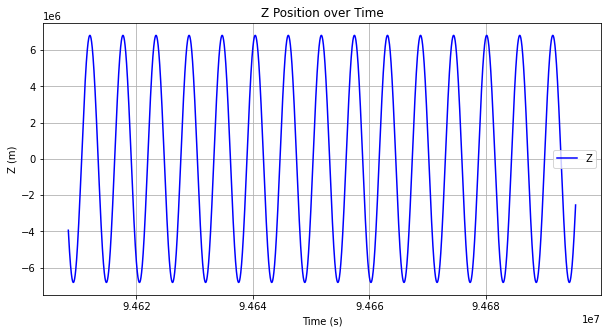

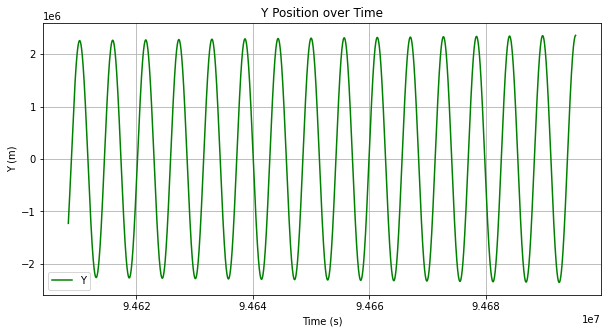

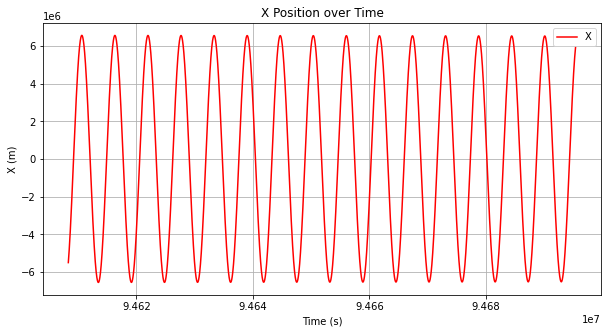

In [12]:
# Plot Z against time
plt.figure(figsize=(10, 5))
plt.plot(df['second'], df['z'], label='Z', color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Z (m)') 
plt.title('Z Position over Time')
plt.grid()
plt.legend()
plt.show()

# Plot Y against time
plt.figure(figsize=(10, 5)) 
plt.plot(df['second'], df['y'], label='Y', color='green')
plt.xlabel('Time (s)')
plt.ylabel('Y (m)')
plt.title('Y Position over Time')
plt.grid()
plt.legend()
plt.show()
# Plot X against time
plt.figure(figsize=(10, 5))
plt.plot(df['second'], df['x'], label='X', color='red')
plt.xlabel('Time (s)')
plt.ylabel('X (m)')
plt.title('X Position over Time')
plt.grid()
plt.legend()
plt.show()

## Remove SAA and Glitches (TODO)

## Project FoV in galactic coordinates (TODO)

### Create map bins

In [13]:
from astropy.coordinates import CartesianRepresentation, GCRS, Galactic, SkyCoord
from astropy import units as u

res_n = 2

# Define the edges of the bins for longitude and latitude
lon_edges = np.linspace(-np.pi, np.pi, int(360 * res_n) + 1)
lat_edges = np.linspace(-np.pi/2, np.pi/2, int(180 * res_n) + 1)

lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])

# Create grid of bin centers
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers, indexing='ij')
grid_coords = SkyCoord(lon_grid.ravel() * u.rad, lat_grid.ravel() * u.rad, frame='galactic')

# Initialize exposure map
exposure_map = np.zeros(lon_grid.shape, dtype=int)
print("Exposure map shape:", exposure_map.shape)
print("Number of timestamps:", len(df['Delta_t']))

Exposure map shape: (720, 360)
Number of timestamps: 87019


### Calculate Zenith unit vector

In [14]:
from astropy.coordinates import CartesianRepresentation

r = np.vstack([df['x'], df['y'], df['z']]).T  # shape: (N, 3)
r_hat = r / np.linalg.norm(r, axis=1)[:, None]  # unit vectors


In [15]:
cartezian_zenith = r_hat
obstime = Time(met_to_utc_string(df['second'].to_numpy(), df['microsecond'].to_numpy()), scale='utc')

In [16]:

# Create GCRS coordinates directly from the Cartesian components
zenith_coords = SkyCoord(
    x=r_hat[:, 0],
    y=r_hat[:, 1],
    z=r_hat[:, 2],
    frame='icrs',
    representation_type=CartesianRepresentation
)
# Transform to galactic coordinates
zenith_coords_gal = zenith_coords.transform_to('galactic')

print(zenith_coords_gal)


<SkyCoord (Galactic): (l, b, distance) in (deg, deg, )
    [(302.67647258,  27.89738709, 1.), (302.66563648,  27.83459508, 1.),
     (302.65481858,  27.77182352, 1.), ...,
     (181.36499749, -80.37551594, 1.), (181.02955394, -80.34626449, 1.),
     (180.69617008, -80.31670216, 1.)]>


### Compute FoV

In [17]:
from astropy.coordinates import angular_separation

def effective_area(cos_theta):
    """
    Compute the effective area based on angular separation.
    This is a placeholder function; replace with actual computation.
    """
    # Example: simple model where effective area decreases with separation
    # This is just an illustrative example; adjust as needed
    return 1

batch_size = 1000
N = zenith_coords_gal.cartesian.xyz.shape[1]  # Number of timestamps
M = grid_coords.cartesian.xyz.shape[1]        # Number of pixels in full sky grid

print("Number of timestamps (N):", N)
print("Number of pixels (M):", M)

# Flatten grid unit vectors into shape (M, 3)
G = grid_coords.cartesian.xyz.value.T  # shape: (M, 3)

# Initialize flat exposure map vector of length M (one per pixel)
exposure_map_flat = np.zeros(M, dtype=np.float64)

for start_idx in range(0, N, batch_size):
    end_idx = min(start_idx + batch_size, N)
    batch_len = end_idx - start_idx

    # Batch of boresight unit vectors: shape (batch_len, 3)
    B = zenith_coords_gal.cartesian.xyz.value.T[start_idx:end_idx]

    # Dot product between each boresight vector and each pixel vector: shape (batch_len, M)
    cos_theta = B @ G.T

    # Mask pixels within 60 degrees (cos_theta >= cos(60°))
    mask = cos_theta >= np.cos(np.radians(60))

    # Prepare increments array: same shape as cos_theta (batch_len, M)
    increments = np.zeros_like(cos_theta)

    # Apply effective_area function only on masked pixels
    increments[mask] = effective_area(cos_theta[mask])

    # Sum increments over timestamps in batch, accumulate into exposure_map_flat
    exposure_map_flat += increments.sum(axis=0)

    print(f"Processed timestamps {start_idx} to {end_idx - 1}")


Number of timestamps (N): 87019
Number of pixels (M): 259200


Processed timestamps 0 to 999
Processed timestamps 1000 to 1999
Processed timestamps 2000 to 2999
Processed timestamps 3000 to 3999
Processed timestamps 4000 to 4999
Processed timestamps 5000 to 5999
Processed timestamps 6000 to 6999
Processed timestamps 7000 to 7999
Processed timestamps 8000 to 8999
Processed timestamps 9000 to 9999
Processed timestamps 10000 to 10999
Processed timestamps 11000 to 11999
Processed timestamps 12000 to 12999
Processed timestamps 13000 to 13999
Processed timestamps 14000 to 14999
Processed timestamps 15000 to 15999
Processed timestamps 16000 to 16999
Processed timestamps 17000 to 17999
Processed timestamps 18000 to 18999
Processed timestamps 19000 to 19999
Processed timestamps 20000 to 20999
Processed timestamps 21000 to 21999
Processed timestamps 22000 to 22999
Processed timestamps 23000 to 23999
Processed timestamps 24000 to 24999
Processed timestamps 25000 to 25999
Processed timestamps 26000 to 26999
Processed timestamps 27000 to 27999
Processed timest

In [18]:

# Reshape exposure map back to the 2D grid shape (e.g. 1440 x 720)
exposure_map = exposure_map_flat.reshape(lon_grid.shape)

print("Exposure map shape:", exposure_map.shape)

Exposure map shape: (720, 360)


## Plot exposure map

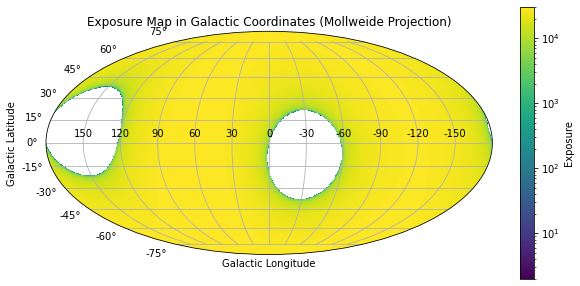

In [19]:
from matplotlib.colors import LogNorm
# Convert your 1D radian lon/lat centers into 2D grid
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers, indexing='ij')

# Convert to Mollweide's expected range: [-π, π] in lon, [-π/2, π/2] in lat
lon_plot = lon_grid.T  # Transpose to match shape
lat_plot = lat_grid.T
exposure_plot = exposure_map.T  # Transpose as well to match pcolormesh layout

# Plot
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111, projection='mollweide')

# Plot with pcolormesh (lon, lat must be in radians)
mesh = ax.pcolormesh(lon_plot, lat_plot, exposure_plot, cmap='viridis', shading='auto', norm=LogNorm())

# Final touches
fig.colorbar(mesh, ax=ax, label='Exposure')
ax.set_title('Exposure Map in Galactic Coordinates (Mollweide Projection)')
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax.set_xticklabels(tick_labels)
ax.set_xlabel('Galactic Longitude')
ax.set_ylabel('Galactic Latitude')
ax.grid(True)

plt.show()

## Show satellite positions in Earth projection 

In [ ]:

def cartesian_to_lat_lon_rotating_earth(x, y, z, time_seconds, reference_time=0):
    """
    Convert Cartesian coordinates (x, y, z) to latitude and longitude,
    accounting for Earth's rotation.
    
    Parameters:
    - x, y, z: Cartesian coordinates in Earth-fixed frame
    - time_seconds: Time in seconds since some reference
    - reference_time: Reference time (seconds) to align with
    """
    # Earth's rotation rate in radians per second
    OMEGA_EARTH = 7.2921159e-5  # rad/s (sidereal rotation rate)
    
    # Calculate radius
    r = np.sqrt(x**2 + y**2 + z**2)
    
    # Calculate latitude (this doesn't change with Earth rotation)
    lat_rad = np.arcsin(z / r)
    lat_deg = np.degrees(lat_rad)
    
    # Calculate longitude in the rotating frame
    lon_rad_rotating = np.arctan2(y, x)
    
    # Convert to inertial frame by removing Earth's rotation
    # Earth rotates eastward, so we subtract the rotation angle
    time_from_ref = time_seconds - reference_time
    earth_rotation_angle = OMEGA_EARTH * time_from_ref
    
    # Longitude in inertial frame (what we actually want to plot)
    lon_rad_inertial = lon_rad_rotating - earth_rotation_angle
    
    # Convert to degrees and normalize to [-180, 180]
    lon_deg = np.degrees(lon_rad_inertial)
    lon_deg = ((lon_deg + 180) % 360) - 180
    
    return lat_deg, lon_deg, r

In [21]:
# Convert satellite positions to lat/lon
df['lat'], df['lon'], df['altitude_from_center'] = cartesian_to_lat_lon(
    df['x'].values, df['y'].values, df['z'].values
)

# Calculate altitude above Earth's surface (assuming Earth radius ~6371 km)
EARTH_RADIUS_KM = 6371.0
df['altitude_km'] = (df['altitude_from_center'] / 1000) - EARTH_RADIUS_KM

print(f"Latitude range: {df['lat'].min():.2f} to {df['lat'].max():.2f} degrees")
print(f"Longitude range: {df['lon'].min():.2f} to {df['lon'].max():.2f} degrees")
print(f"Altitude range: {df['altitude_km'].min():.2f} to {df['altitude_km'].max():.2f} km")


Latitude range: -82.67 to 82.66 degrees
Longitude range: -180.00 to 180.00 degrees
Altitude range: 499.61 to 512.73 km


/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/1

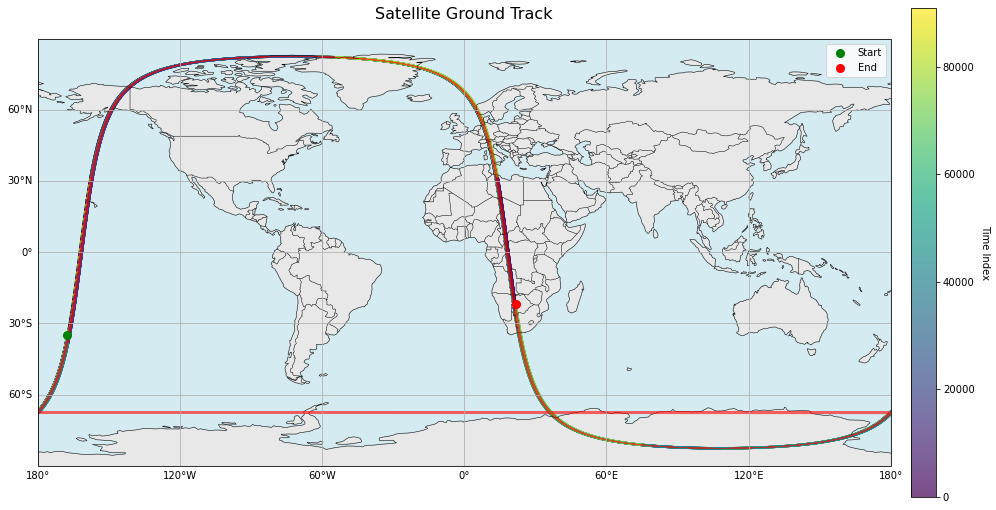

In [22]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create the map plot
fig = plt.figure(figsize=(15, 10))

# Use PlateCarree projection (equirectangular)
ax = plt.axes(projection=ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.5)
ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False

# Plot satellite track
# Color points by time (or altitude)
scatter = ax.scatter(df['lon'], df['lat'], 
                    c=df.index,  # Color by time index
                    s=2, 
                    cmap='viridis', 
                    alpha=0.7,
                    transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('Time Index', rotation=270, labelpad=15)

# Plot the track as a line
ax.plot(df['lon'], df['lat'], 
        color='red', 
        linewidth=0.5, 
        alpha=0.6,
        transform=ccrs.PlateCarree())

# Mark start and end points
ax.plot(df['lon'].iloc[0], df['lat'].iloc[0], 
        'go', markersize=8, label='Start', transform=ccrs.PlateCarree())
ax.plot(df['lon'].iloc[-1], df['lat'].iloc[-1], 
        'ro', markersize=8, label='End', transform=ccrs.PlateCarree())

plt.title('Satellite Ground Track', fontsize=16, pad=20)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()